## 13 — Development-Derived Threshold Analysis

### Methodology & Deployment Simulation

To prevent target leakage and accurately mimic a real-world clinical deployment pipeline, threshold determination and evaluation are strictly partitioned:

#### 1. Threshold Selection (Development Phase Only)
* **Strategy:** Optimal probability decision thresholds are calculated exclusively using predictions from the **train and validation splits**.
* **Youden’s Index:** Optimizes the balance between sensitivity and specificity by maximizing $\text{Sensitivity} + \text{Specificity} - 1$ ($TPF - FPF$).
* **Target Sensitivities ($80\%$ & $90\%$):** Tailored operational points selected to prioritize high recall and minimize false negatives for downstream clinical safety screening.

#### 2. Fixed Threshold Generalization Evaluation
* **Deployment Simulation:** These derived development thresholds are held strictly **unchanged** and applied directly to the independent, held-out **temporal test set**.
* **Objective:** Measures true out-of-time model generalizability and robust real-world performance without data leakage.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Setup and Environment Configuration

We import required data audit tools, configuration parameters, and utilities.

In [2]:
from pathlib import Path
import yaml
import pandas as pd
from icare_risk.evaluation.thresholds import threshold_analysis

# Load configuration
CONFIG_PATH = Path('../../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

# Load predictions and map target labels
prediction_path = Path(config['outputs']['prediction_directory']) / 'admission_predictions.parquet'
predictions = pd.read_parquet(prediction_path)
target = config['columns']['target']
prediction_columns = [c for c in predictions.columns if c.endswith('_prob')]

predictions[target] = predictions[target].map({
    **{str(v): 1 for v in config['target_mapping']['positive_values']},
    **{str(v): 0 for v in config['target_mapping']['negative_values']},
}).fillna(pd.to_numeric(predictions[target], errors='coerce'))
predictions = predictions[predictions[target].isin([0, 1])].copy()

# Run threshold analysis
selected, test_results = threshold_analysis(
    predictions, target, prediction_columns,
    target_sensitivities=(0.80, 0.90),
)
display(selected.head(10))
display(test_results.head(10))

# Save results to disk
output_dir = Path(config['outputs']['metrics_directory'])
output_dir.mkdir(parents=True, exist_ok=True)
selected.to_csv(output_dir / 'development_thresholds.csv', index=False)
test_results.to_csv(output_dir / 'fixed_threshold_test_results.csv', index=False)

print(f'Successfully computed thresholds and saved artifacts to {output_dir}')

,model,prediction_column,threshold_name,threshold
0,lr_kim_components,lr_kim_components_prob,youden,0.503852
1,lr_kim_components,lr_kim_components_prob,sensitivity_0.80,0.503852
2,lr_kim_components,lr_kim_components_prob,sensitivity_0.90,0.503852
3,lr_all_score_values,lr_all_score_values_prob,youden,0.485559
4,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.80,0.502751
5,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.90,0.502751
6,lr_clinical_baseline,lr_clinical_baseline_prob,youden,0.490032
7,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.80,0.467467
8,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.90,0.449368
9,xgb_kim_components,xgb_kim_components_prob,youden,0.199943


,model,prediction_column,threshold_name,threshold,n,events,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,predicted_positive_rate
0,lr_kim_components,lr_kim_components_prob,youden,0.503852,2483,507,453,226,1750,54,0.893491,0.114372,0.205629,0.807143,0.887233
1,lr_kim_components,lr_kim_components_prob,sensitivity_0.80,0.503852,2483,507,453,226,1750,54,0.893491,0.114372,0.205629,0.807143,0.887233
2,lr_kim_components,lr_kim_components_prob,sensitivity_0.90,0.503852,2483,507,453,226,1750,54,0.893491,0.114372,0.205629,0.807143,0.887233
3,lr_all_score_values,lr_all_score_values_prob,youden,0.485559,2483,507,464,173,1803,43,0.915187,0.087551,0.204676,0.800926,0.913008
4,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.80,0.502751,2483,507,453,232,1744,54,0.893491,0.117409,0.206190,0.811189,0.884817
5,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.90,0.502751,2483,507,453,232,1744,54,0.893491,0.117409,0.206190,0.811189,0.884817
6,lr_clinical_baseline,lr_clinical_baseline_prob,youden,0.490032,2483,507,308,765,1211,199,0.607495,0.387146,0.202765,0.793568,0.611760
7,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.80,0.467467,2483,507,410,377,1599,97,0.808679,0.190789,0.204082,0.795359,0.809102
8,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.90,0.449368,2483,507,463,190,1786,44,0.913215,0.096154,0.205869,0.811966,0.905759
9,xgb_kim_components,xgb_kim_components_prob,youden,0.199943,2483,507,453,226,1750,54,0.893491,0.114372,0.205629,0.807143,0.887233


Successfully computed thresholds and saved artifacts to results/metrics


### 2. Receiver Operating Characteristic (ROC) & Operating Points

The ROC curves below illustrate the trade-off between the True Positive Rate (Sensitivity) and False Positive Rate ($1 - \text{Specificity}$) across the primary model architectures during development.

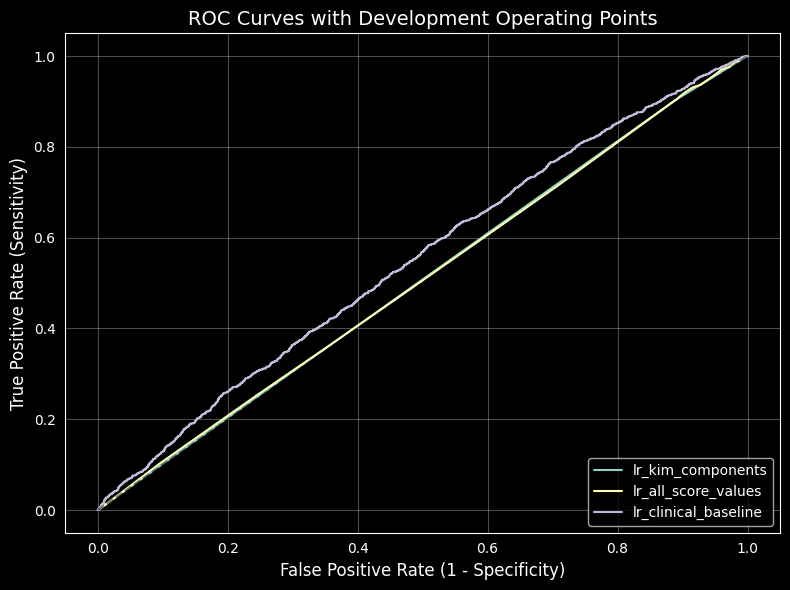

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
development = predictions[predictions['split'].isin(['train', 'validation'])]

for col in prediction_columns[:3]:  # Plot top models for clarity
    model_name = col.removesuffix('_prob')
    y_true = development[target]
    y_prob = development[col]

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f'{model_name}')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curves with Development Operating Points', fontsize=14)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Held-Out Test Performance Summary

The summary table below loads the saved `.csv` artifacts from disk, merges development thresholds with fixed-threshold test results, and presents a styled breakdown of out-of-time generalization metrics.

In [4]:
import pandas as pd

# Load saved metrics
dev_thresholds = pd.read_csv('./results/metrics/development_thresholds.csv')
test_results = pd.read_csv('./results/metrics/fixed_threshold_test_results.csv')

# 5. Automatically create and display a clean summary table
summary_table = pd.merge(
    test_results,
    selected[['model', 'prediction_column', 'threshold_name', 'threshold']],
    on=['model', 'prediction_column', 'threshold_name'],
    suffixes=('_eval', '_dev')
)

display_cols = [
    'model', 'threshold_name', 'threshold_dev',
    'sensitivity', 'specificity', 'ppv', 'npv'
]
table_view = summary_table[display_cols].copy()
table_view.columns = ['Model', 'Strategy', 'Threshold', 'Sensitivity', 'Specificity', 'PPV', 'NPV']

styled_table = table_view.style.format({
    'Threshold': '{:.3f}',
    'Sensitivity': '{:.3f}',
    'Specificity': '{:.3f}',
    'PPV': '{:.3f}',
    'NPV': '{:.3f}'
}).background_gradient(subset=['Sensitivity', 'Specificity'], cmap='Blues')

display(styled_table)

,Model,Strategy,Threshold,Sensitivity,Specificity,PPV,NPV
0,lr_kim_components,youden,0.504,0.893,0.114,0.206,0.807
1,lr_kim_components,sensitivity_0.80,0.504,0.893,0.114,0.206,0.807
2,lr_kim_components,sensitivity_0.90,0.504,0.893,0.114,0.206,0.807
3,lr_all_score_values,youden,0.486,0.915,0.088,0.205,0.801
4,lr_all_score_values,sensitivity_0.80,0.503,0.893,0.117,0.206,0.811
5,lr_all_score_values,sensitivity_0.90,0.503,0.893,0.117,0.206,0.811
6,lr_clinical_baseline,youden,0.490,0.607,0.387,0.203,0.794
7,lr_clinical_baseline,sensitivity_0.80,0.467,0.809,0.191,0.204,0.795
8,lr_clinical_baseline,sensitivity_0.90,0.449,0.913,0.096,0.206,0.812
9,xgb_kim_components,youden,0.200,0.893,0.114,0.206,0.807
